# Pesos, capas y el problema de leer en cadena

**Materiales desarrollados por Matías Barreto, 2026**

**Tecnicatura Superior en Ciencias de Datos e IA, IFTS N.º 24**
* **Nomenclatura oficial:** Procesamiento de Lenguaje Natural
* **Nombre de trabajo:** Laboratorio de PLN: Analítica, Textos y Cultura

---
| | |
|---|---|
| **Problema** | Un modelo debe usar palabras distantes sin reducir toda la secuencia a una memoria única. |
| **Producto** | Una explicación visual de una neurona y una comparación argumentada entre lectura secuencial y atención. |
| **Recursos** | Python, NumPy y Matplotlib; no se descarga ni entrena un modelo. |

En la unidad anterior usamos modelos preentrenados. Ahora abrimos una pieza mínima de esos modelos: una red transforma vectores con pesos que aprende.

**¿Qué cambia cuando una red deja de pasar por el texto de a un token y puede conectar directamente las partes relevantes?**

> **Cómo se trabaja.** Primero explorás cada mecanismo con números pequeños y visualizaciones. Al final de cada bloque hay un microlaboratorio: completás unas líneas y la celda siguiente comprueba el resultado.

In [1]:
import numpy as np

import utils

SEMILLA = 24
np.random.seed(SEMILLA)

print(f"numpy {np.__version__}")
print("La semilla fija solo los ejemplos con azar de este cuaderno.")

numpy 2.5.4
La semilla fija solo los ejemplos con azar de este cuaderno.


## 1. Una palabra llega como un vector

Un modelo no recibe la palabra archivo: recibe un vector. Para no esconder el mecanismo, usamos solo dos dimensiones inventadas. Son **datos sintéticos**: no describen el significado real de las palabras; permiten ver las operaciones.

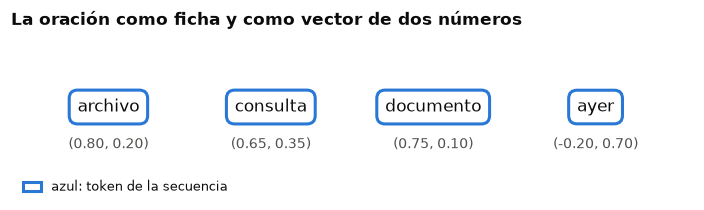

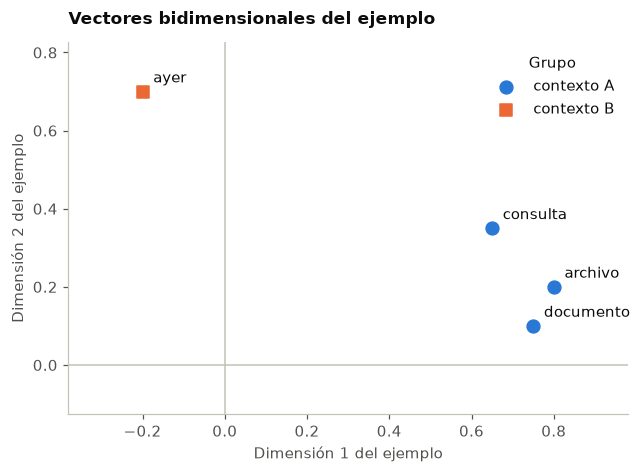

In [2]:
palabras = ["archivo", "consulta", "documento", "ayer"]
vectores = np.array([
    [0.80, 0.20],
    [0.65, 0.35],
    [0.75, 0.10],
    [-0.20, 0.70],
])
grupos = ["contexto A", "contexto A", "contexto A", "contexto B"]

notas = []
for vector in vectores:
    notas.append(f"({vector[0]:.2f}, {vector[1]:.2f})")

# En los titulos de los graficos, la tilde se escribe como una barra
# invertida, una u y cuatro cifras: asi el grafico dibuja la letra.
estilos = {"texto": (utils.AZUL, "azul: token de la secuencia")}
utils.dibujar_fichas(
    piezas=palabras,
    clases=["texto"] * len(palabras),
    estilos=estilos,
    titulo="La oraci\u00f3n como ficha y como vector de dos n\u00fameros",
    notas=notas,
)
utils.dibujar_dispersion(
    coordenadas=vectores,
    grupos=grupos,
    etiquetas=palabras,
    titulo="Vectores bidimensionales del ejemplo",
)

> **Para mirar.** La dispersión muestra exactamente las dos dimensiones que inventamos; no es una proyección ni demuestra que dos palabras tengan un significado semejante. Lo importante es que una capa puede operar sobre números, no sobre las letras de la palabra.

## 2. Una neurona cambia un vector con pesos

Una capa lineal multiplica cada componente por un peso y suma un sesgo. Durante el entrenamiento, se ajustan esos pesos para reducir un error. En este ejemplo no entrenamos: inspeccionamos un cálculo ya fijado.

contribuciones: [ 0.48 -0.08]
salida lineal: 0.50


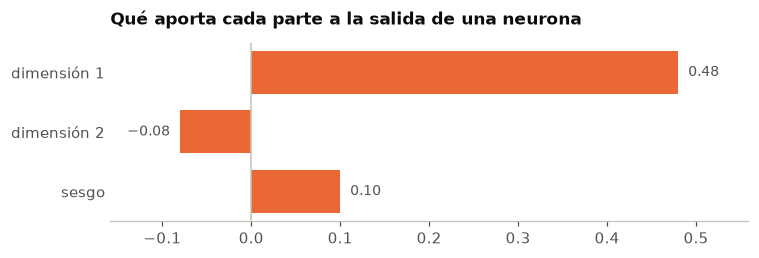

In [3]:
vector_entrada = np.array([0.80, 0.20])
pesos = np.array([0.60, -0.40])
sesgo = 0.10

contribuciones = vector_entrada * pesos
salida = contribuciones.sum() + sesgo

print(f"contribuciones: {contribuciones}")
print(f"salida lineal: {salida:.2f}")
utils.dibujar_barras(
    nombres=["dimensi\u00f3n 1", "dimensi\u00f3n 2", "sesgo"],
    valores=[contribuciones[0], contribuciones[1], sesgo],
    titulo="Qu\u00e9 aporta cada parte a la salida de una neurona",
    color=utils.NARANJA,
)

> **Para mirar.** El segundo componente no desaparece: su peso negativo resta a la salida. Decir que una red mira una característica significa, en este nivel, que aprendió pesos que modifican cuánto aporta cada número.

## 3. Leer en cadena obliga a transportar el contexto

Una RNN entrega un estado de un paso al siguiente. Eso conserva orden, pero una pista del comienzo debe atravesar todos los estados intermedios para influir al final. Las barras siguientes son un **modelo visual sintético**, no una medición de una RNN entrenada.

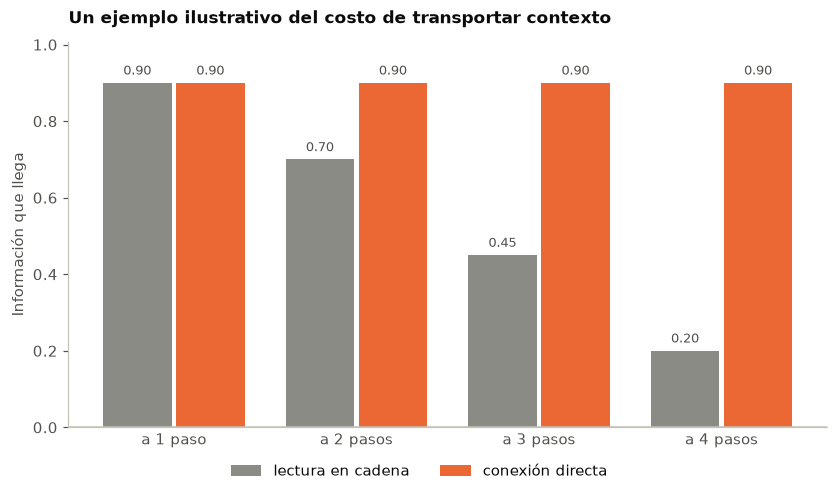

In [4]:
distancias = ["a 1 paso", "a 2 pasos", "a 3 pasos", "a 4 pasos"]
retencion_rnn = [0.90, 0.70, 0.45, 0.20]
conexion_directa = [0.90, 0.90, 0.90, 0.90]

utils.dibujar_barras_agrupadas(
    categorias=distancias,
    series={
        "lectura en cadena": retencion_rnn,
        "conexi\u00f3n directa": conexion_directa,
    },
    titulo="Un ejemplo ilustrativo del costo de transportar contexto",
    etiqueta_y="Informaci\u00f3n que llega",
)

> **Para mirar.** La lectura en cadena no es inútil: fue un avance frente a bolsa de palabras porque respeta el orden. Pero para relacionar archivo con una palabra lejana, debe hacer circular información por todos los pasos. Attention propondrá calcular relaciones directas entre pares de tokens.

### Microlaboratorio 1 — Cambiar el peso cambia la salida

**Tarea.** Probá una neurona con un peso que ahora favorece la segunda dimensión.  
**Producto.** Una salida lineal positiva y comprobada.

| Línea | Qué tiene que quedar | Con qué |
|---|---|---|
| (1) | un peso positivo para la segunda dimensión | un número mayor que cero |
| (2) | la nueva salida | suma de las contribuciones y el sesgo |

> **Ayuda 1.** Releé la celda de la sección 2: la multiplicación es elemento a elemento.  
> **Ayuda 2.** Si el segundo peso es 0.40, ambas contribuciones suman antes de agregar el sesgo.

In [5]:
pesos_nuevos = np.array([0.60, 0.00])  # COMPLETAR (1)
contribuciones_nuevas = vector_entrada * pesos_nuevos
salida_nueva = 0.0  # COMPLETAR (2)

print(f"salida nueva: {salida_nueva:.2f}")
utils.comprobar(
    np.isclose(salida_nueva, 0.66),
    "revisa el segundo peso y suma las dos contribuciones con el sesgo.",
)

salida nueva: 0.00
Todavia no. revisa el segundo peso y suma las dos contribuciones con el sesgo.


## Qué te llevás

- Una capa transforma vectores con pesos y un sesgo; aprender modifica esos parámetros a partir de un error.
- Una RNN hace circular un estado en orden; así, las relaciones lejanas deben atravesar pasos intermedios.
- Attention conserva los vectores, pero cambia el mecanismo para combinar contexto.

**Sigue:** cada token consultará a los demás, primero sin aprender y después con consultas, claves y valores.